In [45]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report
from sklearn.ensemble import RandomForestClassifier

from imblearn.over_sampling import SMOTE

from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report
from sklearn.metrics import accuracy_score
from sklearn.metrics import roc_auc_score

import joblib


In [2]:
df = pd.read_csv("Fraud.csv")

In [7]:
df.head()

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0


In [6]:
df.tail()

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
6362615,743,CASH_OUT,339682.13,C786484425,339682.13,0.0,C776919290,0.00,339682.13,1,0
6362616,743,TRANSFER,6311409.28,C1529008245,6311409.28,0.0,C1881841831,0.00,0.00,1,0
6362617,743,CASH_OUT,6311409.28,C1162922333,6311409.28,0.0,C1365125890,68488.84,6379898.11,1,0
6362618,743,TRANSFER,850002.52,C1685995037,850002.52,0.0,C2080388513,0.00,0.00,1,0
6362619,743,CASH_OUT,850002.52,C1280323807,850002.52,0.0,C873221189,6510099.11,7360101.63,1,0


In [8]:
df.shape

(6362620, 11)

In [9]:
df.info

<bound method DataFrame.info of          step      type      amount     nameOrig  ...  oldbalanceDest  newbalanceDest isFraud  isFlaggedFraud
0           1   PAYMENT     9839.64  C1231006815  ...            0.00            0.00       0               0
1           1   PAYMENT     1864.28  C1666544295  ...            0.00            0.00       0               0
2           1  TRANSFER      181.00  C1305486145  ...            0.00            0.00       1               0
3           1  CASH_OUT      181.00   C840083671  ...        21182.00            0.00       1               0
4           1   PAYMENT    11668.14  C2048537720  ...            0.00            0.00       0               0
...       ...       ...         ...          ...  ...             ...             ...     ...             ...
6362615   743  CASH_OUT   339682.13   C786484425  ...            0.00       339682.13       1               0
6362616   743  TRANSFER  6311409.28  C1529008245  ...            0.00            0.00   

In [10]:
df.isnull().sum()

step              0
type              0
amount            0
nameOrig          0
oldbalanceOrg     0
newbalanceOrig    0
nameDest          0
oldbalanceDest    0
newbalanceDest    0
isFraud           0
isFlaggedFraud    0
dtype: int64

In [11]:
df.duplicated().sum()

np.int64(0)

In [12]:
df['type'].unique()

array(['PAYMENT', 'TRANSFER', 'CASH_OUT', 'DEBIT', 'CASH_IN'],
      dtype=object)

In [13]:
df['type'].value_counts()

type
CASH_OUT    2237500
PAYMENT     2151495
CASH_IN     1399284
TRANSFER     532909
DEBIT         41432
Name: count, dtype: int64

In [14]:
df['isFraud'].value_counts()

isFraud
0    6354407
1       8213
Name: count, dtype: int64

In [15]:
# checking percentage of fraud counts
(df['isFraud'].value_counts(normalize=True)) * 100

isFraud
0    99.870918
1     0.129082
Name: proportion, dtype: float64

## Data Cleaning

In [5]:
df.isnull().sum()

step              0
type              0
amount            0
nameOrig          0
oldbalanceOrg     0
newbalanceOrig    0
nameDest          0
oldbalanceDest    0
newbalanceDest    0
isFraud           0
isFlaggedFraud    0
dtype: int64

In [19]:
df.duplicated().sum()

np.int64(0)

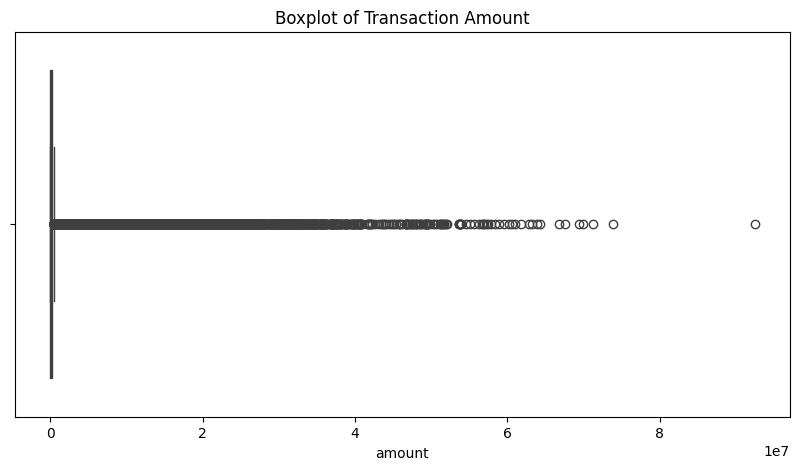

In [20]:
# checking outliers
plt.figure(figsize=(10,5))

sns.boxplot(x=df['amount'])

plt.title("Boxplot of Transaction Amount")

plt.show()

In [21]:
le = LabelEncoder()

df['type'] = le.fit_transform(df['type'])

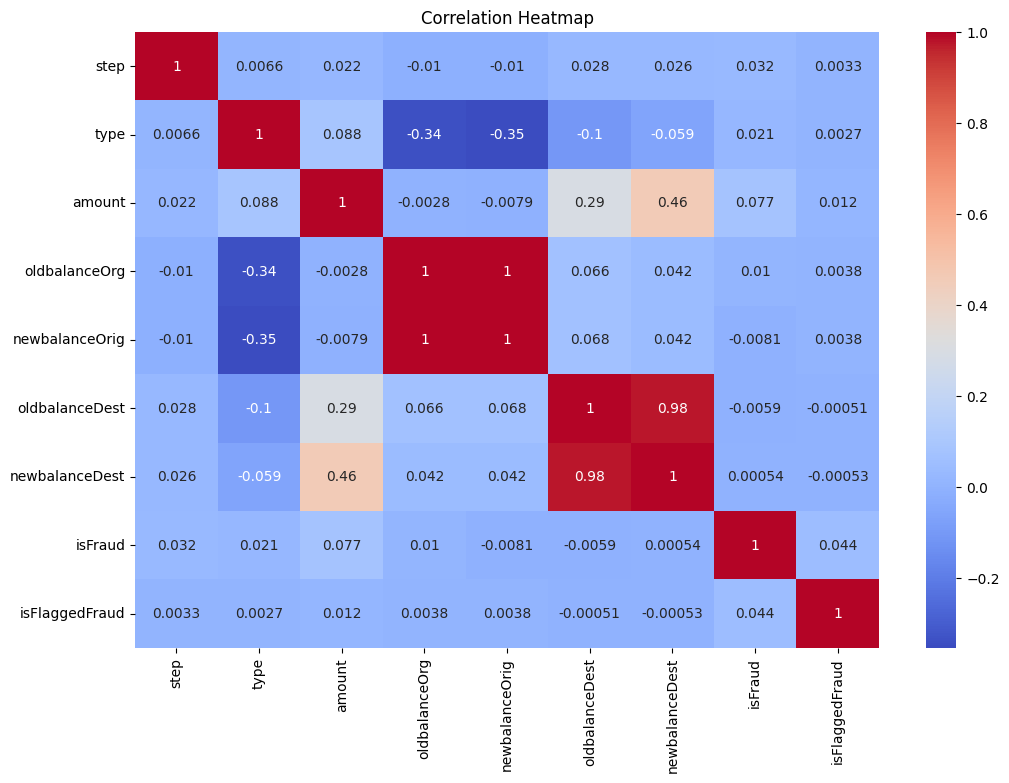

In [23]:
plt.figure(figsize=(12,8))

numeric_df = df.select_dtypes(include=['int64', 'float64'])

sns.heatmap(numeric_df.corr(), annot=True, cmap='coolwarm')

plt.title("Correlation Heatmap")

plt.show()

## Exploratory Data Analysis

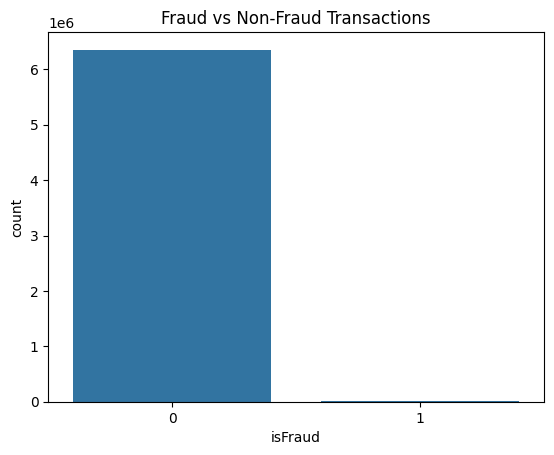

In [24]:
# Fraud vs Non-Fraud Transactions

sns.countplot(x='isFraud', data=df)

plt.title("Fraud vs Non-Fraud Transactions")

plt.show()

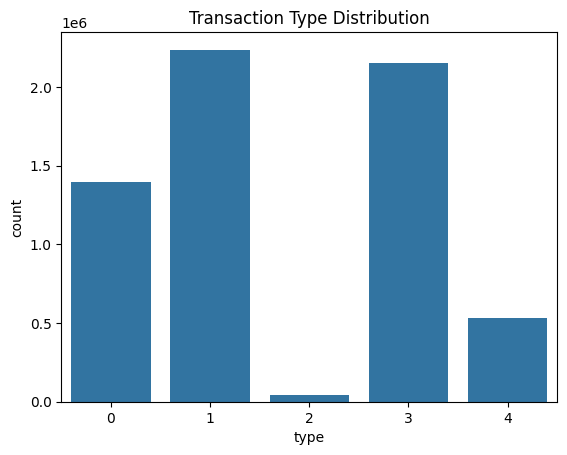

In [25]:
# Transaction Type Distribution

sns.countplot(x='type', data=df)

plt.title("Transaction Type Distribution")

plt.show()

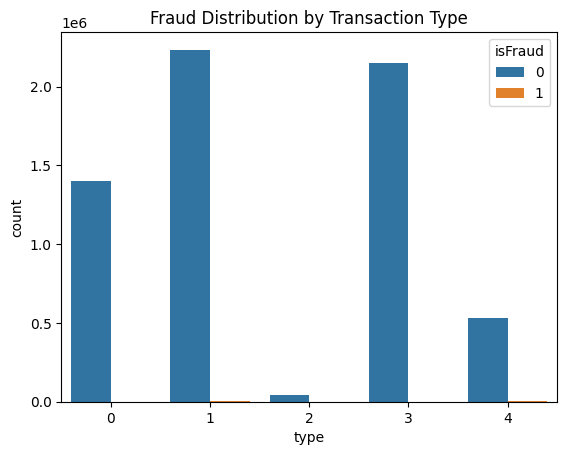

In [26]:
# Fraud by Transaction Type

sns.countplot(x='type', hue='isFraud', data=df)

plt.title("Fraud Distribution by Transaction Type")

plt.show()

## Feature Engineering

In [28]:
df['balanceDiffOrig'] = df['oldbalanceOrg'] - df['newbalanceOrig']

df['balanceDiffDest'] = df['newbalanceDest'] - df['oldbalanceDest']

In [29]:
df.head()

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud,balanceDiffOrig,balanceDiffDest
0,1,3,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0,9839.64,0.0
1,1,3,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0,1864.28,0.0
2,1,4,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0,181.00,0.0
3,1,1,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0,181.00,-21182.0
4,1,3,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0,11668.14,0.0


In [34]:
X = df.drop(['isFraud', 'nameOrig', 'nameDest'], axis=1)

y = df['isFraud']

## Splitting Data and Training Model

In [35]:
# Stratified split maintains fraud ratio in both train and test sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

In [36]:
smote = SMOTE(random_state=42)

X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

print(y_train_smote.value_counts())

isFraud
0    5083526
1    5083526
Name: count, dtype: int64


In [37]:
# Random Forest Model

rf = RandomForestClassifier(
    n_estimators=200,
    max_depth=15,
    min_samples_split=5,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

# Train model

rf.fit(X_train_smote, y_train_smote)

,n_estimators,200
,criterion,'gini'
,max_depth,15
,min_samples_split,5
,min_samples_leaf,2
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [39]:
# Make predictions

y_pred = rf.predict(X_test)

## Evaluation

In [41]:
print(confusion_matrix(y_test, y_pred))

[[1267460    3421]
 [     29    1614]]


In [42]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00   1270881
           1       0.32      0.98      0.48      1643

    accuracy                           1.00   1272524
   macro avg       0.66      0.99      0.74   1272524
weighted avg       1.00      1.00      1.00   1272524



In [43]:
print("Accuracy Score:", accuracy_score(y_test, y_pred))

Accuracy Score: 0.9972888527053321


In [44]:
print("ROC-AUC Score:", roc_auc_score(y_test, y_pred))

ROC-AUC Score: 0.9898287637323633


## Exporting Model

In [46]:
# Save trained model

joblib.dump(rf, 'fraud_detection_model.pkl')

print("Model saved successfully")

Model saved successfully
